In [1]:
import sys
sys.path.append("..")

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve

from ml.train_model import (
    load_train_test, get_models, evaluate_model, MODEL_DIR, RANDOM_STATE,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

FIG_DIR = Path("../static/images/ml")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(f"Default % train: {y_train.mean() * 100:.1f} | test: {y_test.mean() * 100:.1f}")

X_train: (25927, 20) | X_test: (6482, 20)
Default % train: 21.9 | test: 21.9


In [3]:
models = get_models()
for name, m in models.items():
    print(f"{name:22s}->", m)

Logistic Regression   -> LogisticRegression(max_iter=1000, random_state=42)
Decision Tree         -> DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=42)
Random Forest         -> RandomForestClassifier(max_depth=12, min_samples_leaf=5, n_estimators=200,
                       n_jobs=-1, random_state=42)


In [4]:
for name, m in models.items():
    t = time.time()
    m.fit(X_train, y_train)
    print(f"{name:22s} trained in {time.time() - t:5.1f} sec")

Logistic Regression    trained in   0.2 sec
Decision Tree          trained in   0.1 sec
Random Forest          trained in   1.7 sec


In [5]:
rows = []
for name, m in models.items():
    test_scores = evaluate_model(m, X_test, y_test)
    train_acc = evaluate_model(m, X_train, y_train)["Accuracy"]
    rows.append({"Model": name, **test_scores, "Train Accuracy": train_acc})

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC,Train Accuracy
Model,,,,,,
Logistic Regression,0.858,0.740,0.539,0.624,0.871,0.862
Decision Tree,0.933,0.988,0.701,0.820,0.907,0.928
Random Forest,0.935,0.977,0.719,0.829,0.931,0.937


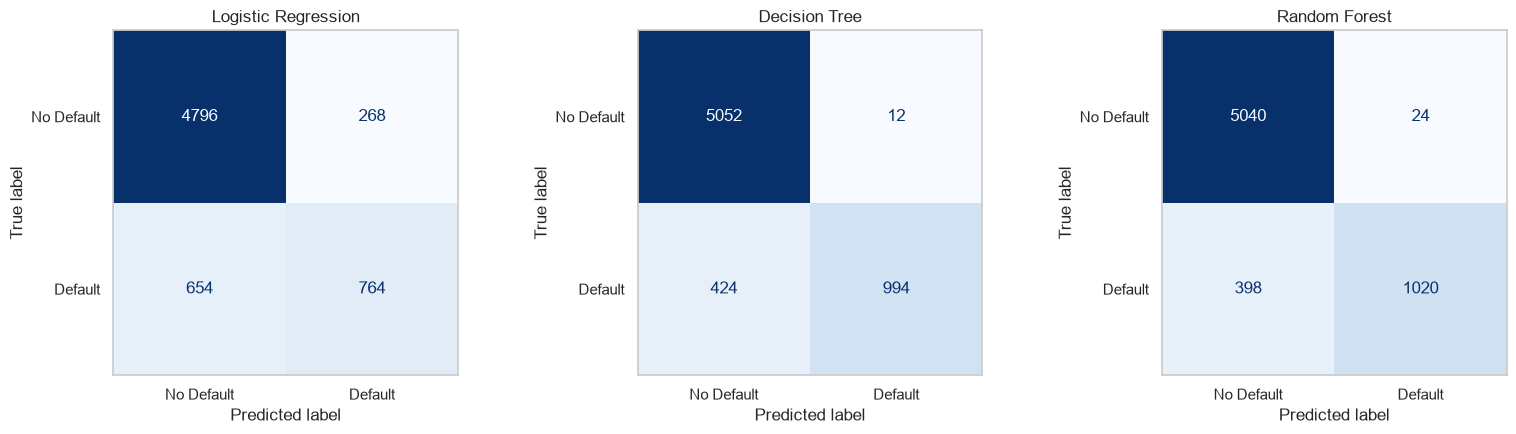

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, m) in zip(axes, models.items()):
    pred = (m.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["No Default", "Default"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_confusion_matrices.png", dpi=120)
plt.show()

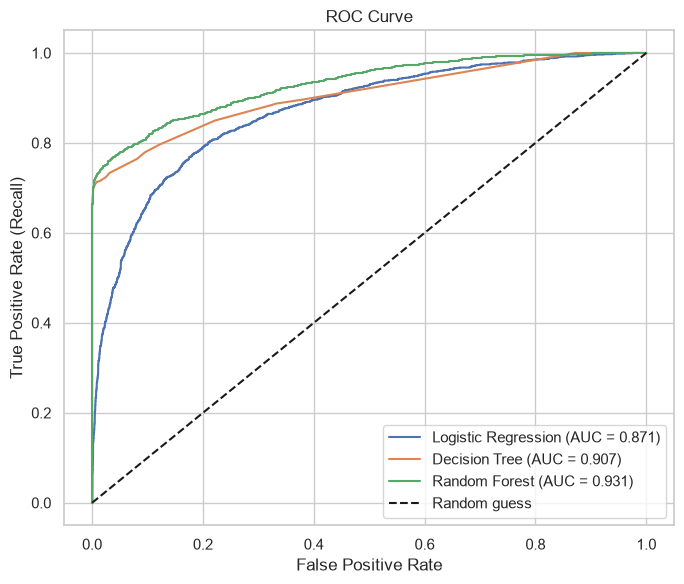

In [7]:
plt.figure(figsize=(7, 6))
for name, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_roc_curves.png", dpi=120)
plt.show()

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, m in get_models().items():            # fresh models
    scores = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_rows.append({"Model": name, "CV ROC-AUC (mean)": scores.mean(), "CV std": scores.std()})

pd.DataFrame(cv_rows).set_index("Model").round(4)

,CV ROC-AUC (mean),CV std
Model,,
Logistic Regression,0.8690,0.0039
Decision Tree,0.9039,0.0019
Random Forest,0.9268,0.0038


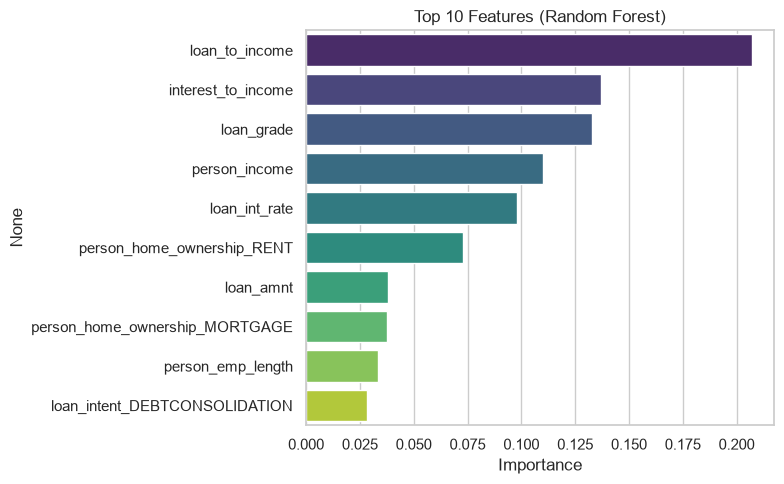

loan_to_income                    20.7 %
interest_to_income                13.7 %
loan_grade                        13.3 %
person_income                     11.0 %
loan_int_rate                      9.8 %
person_home_ownership_RENT         7.3 %
loan_amnt                          3.8 %
person_home_ownership_MORTGAGE     3.8 %
person_emp_length                  3.3 %
loan_intent_DEBTCONSOLIDATION      2.8 %
dtype: str


In [9]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
imp.index = [i.split("__", 1)[1] for i in imp.index]

top10 = imp.head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette="viridis", legend=False)
plt.title("Top 10 Features (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_feature_importance.png", dpi=120)
plt.show()

print((top10 * 100).round(1).astype(str) + " %")

In [10]:
proba = models["Random Forest"].predict_proba(X_test)[:, 1]

rows = []
for th in [0.2, 0.3, 0.4, 0.5, 0.6]:
    s = evaluate_model(models["Random Forest"], X_test, y_test, threshold=th)
    flagged = (proba >= th).mean()
    rows.append({"Threshold": th, "Precision": s["Precision"], "Recall": s["Recall"],
                 "F1": s["F1"], "Flagged as Default %": flagged * 100})

pd.DataFrame(rows).set_index("Threshold").round(3)

,Precision,Recall,F1,Flagged as Default %
Threshold,,,,
0.2,0.717,0.803,0.758,24.499
0.3,0.873,0.760,0.813,19.022
0.4,0.942,0.735,0.826,17.063
0.5,0.977,0.719,0.829,16.106
0.6,0.986,0.702,0.820,15.582


In [11]:
param_grid = {
    "max_depth": [8, 12, 16],
    "min_samples_leaf": [2, 5],
}

grid = GridSearchCV(
    RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    param_grid, cv=3, scoring="roc_auc", n_jobs=1, verbose=1,
)
grid.fit(X_train, y_train)

print("Best params :", grid.best_params_)
print(f"Best CV AUC : {grid.best_score_:.4f}")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best params : {'max_depth': 16, 'min_samples_leaf': 2}
Best CV AUC : 0.9293


In [12]:
tuned = grid.best_estimator_
tuned_scores = evaluate_model(tuned, X_test, y_test)

compare = pd.DataFrame({
    "Random Forest (default)": results.loc["Random Forest", ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]],
    "Random Forest (tuned)": pd.Series(tuned_scores),
}).T.round(4)
compare

,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest (default),0.9350,0.9770,0.7190,0.8290,0.931
Random Forest (tuned),0.9347,0.9743,0.7207,0.8285,0.935


In [13]:
final = results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].copy()
final.loc["Random Forest (tuned)"] = pd.Series(tuned_scores).round(3)
final = final.sort_values("ROC-AUC", ascending=False)
print(final)

best_name = final.index[0]
print()
print("BEST MODEL (highest ROC-AUC):", best_name)

info = {
    "model_name": "Random Forest",
    "params": {**grid.best_params_, "n_estimators": 200, "random_state": RANDOM_STATE},
    "metrics": {k: round(float(v), 4) for k, v in tuned_scores.items()},
}
MODEL_DIR.mkdir(parents=True, exist_ok=True)
final.to_csv(MODEL_DIR / "model_comparison.csv")
with open(MODEL_DIR / "best_model_info.json", "w") as f:
    json.dump(info, f, indent=2)

print("Saved: ml/saved_models/model_comparison.csv")
print("Saved: ml/saved_models/best_model_info.json")

                       Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                             
Random Forest (tuned)     0.935      0.974   0.721  0.829    0.935
Random Forest             0.935      0.977   0.719  0.829    0.931
Decision Tree             0.933      0.988   0.701  0.820    0.907
Logistic Regression       0.858      0.740   0.539  0.624    0.871

BEST MODEL (highest ROC-AUC): Random Forest (tuned)
Saved: ml/saved_models/model_comparison.csv
Saved: ml/saved_models/best_model_info.json
